# Imports

In [46]:
import subprocess
import os
import glob
import sys
sys.path.append("..")
rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)

from rstools import RSoftCircuit
import rsoft_lib

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm
import linecache

from tqdm import tqdm

# Version 1
### (a) 2x2 MMI, two input fiber mode injection
Scan in wavelength and phase

In [6]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = "2x2MMI_FiberTwoInput_scan_Wav_Phase"
filename = "2x2MMI_FiberTwoInput.ind"
wav_arr = np.linspace(1.45, 1.65, 11)
phase_arr = np.linspace(0, 180, 11)

# Make scan save directory if it doesn't exist
os.makedirs(f"{working_dir}/{save_dir}/", exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    for phase in tqdm(phase_arr, desc=f"Phase loop (Wavelength: {wav} microns)", position=1, leave=False): 
        # Set wavelength and phase in .ind file
        c = RSoftCircuit()
        c.read(working_dir+filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("PhaseShift", phase)
        c.write(working_dir+filename)
        
        # Define the command and arguments
        wav_str = f"{wav:0.3f}".replace(".", "p")
        phase_str = f"{phase:0.3f}".replace(".", "p")
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{save_dir}_Wav{wav_str}_Phase{phase_str}", "wait=0"]
    
        # Run the command
        result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

 45%|█████████████████████████████████████▎                                            | 5/11 [17:32<21:07, 211.22s/it]
Phase loop (Wavelength: 1.5499999999999998 microns):   0%|                                      | 0/11 [00:00<?, ?it/s]
Phase loop (Wavelength: 1.5499999999999998 microns):   9%|██▋                           | 1/11 [00:19<03:18, 19.86s/it]
Phase loop (Wavelength: 1.5499999999999998 microns):  18%|█████▍                        | 2/11 [00:39<02:57, 19.73s/it]
Phase loop (Wavelength: 1.5499999999999998 microns):  27%|████████▏                     | 3/11 [00:58<02:35, 19.48s/it]
Phase loop (Wavelength: 1.5499999999999998 microns):  36%|██████████▉                   | 4/11 [01:18<02:16, 19.50s/it]
Phase loop (Wavelength: 1.5499999999999998 microns):  45%|█████████████▋                | 5/11 [01:38<01:58, 19.73s/it]
Phase loop (Wavelength: 1.5499999999999998 microns):  55%|████████████████▎             | 6/11 [01:58<01:40, 20.02s/it]
Phase loop (Wavelength: 1.54999999999999

### (b) 2x2 MMI, field input

Scan wavelength, phi, and theta

In [ ]:
component_name, device_name, input_name = '2x2MMI_FieldInput', '2x2MZI', '2x2MMI_FiberTwoInput'
device_dir = f"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = f"{device_dir}\\{device_name}_scan_Wav_Phi_Theta\\"
input_dir = f"{device_dir}\\{input_name}_scan_Wav_Phase\\"

mon_dir = glob.glob(f"{input_dir}*.mon")
wav_arr = np.sort(np.array(list(set([float(path.split('Wav')[-1].split('_')[0].replace('p', '.')) for path in mon_dir]))))
phi_arr = np.sort(np.array(list(set([float(path.split('Phase')[-1].split('.mon')[0].replace('p', '.')) for path in mon_dir]))))
theta_arr = np.copy(phi_arr)

TaperGap = rsoft_lib.read_symbol(filename, "TaperGap")
TaperWidth = rsoft_lib.read_symbol(filename, "TaperWidth")
BendOffset = rsoft_lib.read_symbol(filename, "BendOffset")
MMISlabWidth = rsoft_lib.read_symbol(filename, "MMISlabWidth")
waveguide_width = rsoft_lib.read_symbol(filename, "width")
waveguide_height = waveguide_width
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset

launch_position = 0

# Make scan save directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for phi in tqdm(phi_arr, desc=f"Phi loop (Wavelength: {wav} microns)", position=1, leave=False): 
        phi_str = f"{phi:0.3f}".replace(".", "p")
        input_field = f"{device_dir}{input_name}_scan_Wav_Phase_Wav{wav_str}_Phase{phi_str}.fld"
        for theta in tqdm(phi_arr, desc=f"Theta loop (Wavelength: {wav} microns, Phi: {phi} deg)", position=1, leave=False):
            theta_str = f"{theta:0.3f}".replace(".", "p")
            rsoft_lib.phase_field(input_field, theta, right=True)
            
            # Set wavelength and phase in .ind file
            c = RSoftCircuit()
            c.read(filename)
            c.set_symbol("free_space_wavelength", wav)
            c.set_symbol("launch_file", f'{device_dir}/Phased_field.fld')
            c.set_symbol("launch_position", launch_position)
            c.write(filename)
            
            # Define the command and arguments
            command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{device_name}_Wav{wav_str}_Phi{phi_str}_Theta{theta_str}", "wait=0"]
        
            # Run the command
            result = subprocess.run(command, cwd=component_dir, capture_output=True, text=True)
    
            x, y, field_amp, field_phase = rsoft_lib.read_field(f"{save_dir}/{device_name}_Wav{wav_str}_Phi{phi_str}_Theta{theta_str}.fld")
        
            fig, ax = plt.subplots(figsize=(20,6))
            im = plt.pcolormesh(x, y, field_amp)
            square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                            linewidth=1, edgecolor='r', facecolor='none')
            square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                             linewidth=1, edgecolor='r', facecolor='none')
            ax.add_patch(square_left)
            ax.add_patch(square_right)
            plt.xlabel('x (microns)')
            plt.ylabel('y (microns)')
            plt.colorbar(im)
            plt.show()
            
            fig, ax = plt.subplots(figsize=(20,6))
            im = plt.pcolormesh(x, y, field_phase, cmap='hsv')
            # im = plt.pcolormesh(x_right, y, field_phase_right.T, cmap='hsv')
            square_left = patches.Rectangle((tricoupler_left_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                            linewidth=1, edgecolor='r', facecolor='none')
            square_right = patches.Rectangle((tricoupler_right_x-waveguide_width/2, 0-waveguide_height/2), waveguide_width, waveguide_height, 
                                             linewidth=1, edgecolor='r', facecolor='none')
            ax.add_patch(square_left)
            ax.add_patch(square_right)
            plt.xlabel('x (microns)')
            plt.ylabel('y (microns)')
            plt.colorbar(im)
            plt.show()

# Version 2
### (a) 2x2 MMI, two input fiber mode injection
Scan in wavelength

In [7]:
working_dir = r"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = "2x2MMI_FiberTwoInput_scan_Wav"
filename = "2x2MMI_FiberTwoInput.ind"
wav_arr = np.linspace(1.45, 1.65, 11)

# Make scan save directory if it doesn't exist
os.makedirs(f"{working_dir}/{save_dir}/", exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    # Set wavelength and phase in .ind file
    c = RSoftCircuit()
    c.read(working_dir+filename)
    c.set_symbol("free_space_wavelength", wav)
    c.set_symbol("PhaseShift", 0)
    c.write(working_dir+filename)
    
    # Define the command and arguments
    wav_str = f"{wav:0.3f}".replace(".", "p")
    command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{save_dir}_Wav{wav_str}", "wait=0"]

    # Run the command
    result = subprocess.run(command, cwd=working_dir, capture_output=True, text=True)

100%|██████████████████████████████████████████████████████████████████████████████████| 11/11 [03:22<00:00, 18.38s/it]


### (b) 2x2 MMI, field input

Scan wavelength and theta (add phi after the fact)

In [16]:
component_name, device_name, input_name = '2x2MMI_FieldInput', '2x2MZI', '2x2MMI_FiberTwoInput'
device_dir = f"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = f"{device_dir}\\{device_name}_scan_Wav_Theta\\"
input_dir = f"{device_dir}\\{input_name}_scan_Wav\\"
filename = f"{component_name}.ind"

mon_dir = glob.glob(f"{input_dir}*.mon")
wav_arr = np.sort(np.array(list(set([float(path.split('Wav')[-1].split('.')[0].replace('p', '.')) for path in mon_dir]))))
theta_arr = np.linspace(0, 360, 21)

TaperGap = rsoft_lib.read_symbol(filename, "TaperGap")
TaperWidth = rsoft_lib.read_symbol(filename, "TaperWidth")
BendOffset = rsoft_lib.read_symbol(filename, "BendOffset")
MMISlabWidth = rsoft_lib.read_symbol(filename, "MMISlabWidth")
waveguide_width = rsoft_lib.read_symbol(filename, "width")
waveguide_height = waveguide_width
tricoupler_left_x = -(TaperGap+TaperWidth)/2-BendOffset
tricoupler_right_x = (TaperGap+TaperWidth)/2+BendOffset

launch_position = 0

# Make scan save directory if it doesn't exist
os.makedirs(save_dir, exist_ok=True)

# Conduct scan
for wav in tqdm(wav_arr):
    wav_str = f"{wav:0.3f}".replace(".", "p")
    for theta in tqdm(theta_arr, desc=f"Theta loop (Wavelength: {wav} microns)", position=1, leave=False): 
        theta_str = f"{theta:0.3f}".replace(".", "p")
        input_field = f"{device_dir}{input_name}_scan_Wav\\{input_name}_scan_Wav_Wav{wav_str}.fld"
        rsoft_lib.phase_field(input_field, theta, right=True)
        
        # Set wavelength and phase in .ind file
        c = RSoftCircuit()
        c.read(filename)
        c.set_symbol("free_space_wavelength", wav)
        c.set_symbol("launch_file", f'{device_dir}/Phased_field.fld')
        c.set_symbol("launch_position", launch_position)
        c.write(filename)
        
        # Define the command and arguments
        command = ["bsimw32", "-min", filename, f"prefix={save_dir}/{device_name}_Wav{wav_str}_Theta{theta_str}", "wait=0"]
    
        # Run the command
        result = subprocess.run(command, cwd=device_dir, capture_output=True, text=True)

100%|███████████████████████████████████████████████████████████████████████████████| 11/11 [1:47:07<00:00, 584.35s/it]


In [29]:
device_name = '2x2MZI'
device_dir = f"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = f"{device_dir}\\{device_name}_scan_Wav_Theta\\"
mon_dir = glob.glob(f"{save_dir}{device_name}*.mon")
wav_arr = np.sort(np.array(list(set([float(path.split('Wav')[-1].split('_')[0].replace('p', '.')) for path in mon_dir]))))
theta_arr = np.sort(np.array(list(set([float(path.split('Theta')[-1].split('.')[0].replace('p', '.')) for path in mon_dir]))))
wav_arr, theta_arr

(array([1.45, 1.47, 1.49, 1.51, 1.53, 1.55, 1.57, 1.59, 1.61, 1.63, 1.65]),
 array([  0.,  18.,  36.,  54.,  72.,  90., 108., 126., 144., 162., 180.]))

In [48]:
device_name = '2x2MZI'
device_dir = f"C:\\Users\\runner\\ActivePIC\\2x2MMI\\"
save_dir = f"{device_dir}\\{device_name}_scan_Wav_Theta\\"
mon_dir = glob.glob(f"{save_dir}{device_name}*.mon")
wav_arr = np.sort(np.array(list(set([float(path.split('Wav')[-1].split('_')[0].replace('p', '.')) for path in mon_dir]))))
theta_arr = np.sort(np.array(list(set([float(path.split('Theta')[-1].split('.')[0].replace('p', '.')) for path in mon_dir]))))

outputs_A_amp, outputs_B_amp, outputs_A_phase, outputs_B_phase = [], [], [], []
for wav in wav_arr:
    wav_str = f"{wav:.3f}".replace('.', 'p')
    output_A_amp, output_B_amp, output_A_phase, output_B_phase = [], [], [], []
    for theta in theta_arr:
        theta_str = f"{theta:.3f}".replace('.', 'p')
        filename = save_dir+f"\\{device_name}_Wav{wav_str}_Theta{theta_str}.mon"
        sim = np.genfromtxt(filename, skip_header=5)       
        output_A_amp.append(sim[-1,1])
        output_B_amp.append(sim[-1,2])
        output_A_phase.append(sim[-1,3])
        output_B_phase.append(sim[-1,4])
    outputs_A_amp.append(output_A_amp)
    outputs_B_amp.append(output_B_amp)
    outputs_A_phase.append(output_A_phase)
    outputs_B_phase.append(output_B_phase)
outputs_A_amp, outputs_B_amp, outputs_A_phase, outputs_B_phase = np.array(outputs_A_amp), np.array(outputs_B_amp), np.array(outputs_A_phase), np.array(outputs_B_phase)

# fig, ax = plt.subplots(1, 1, figsize=(10,6))
# ax.plot(wav_arr, outputs_A_amp[0], color='k', label='Output A')
# ax.plot(wav_arr, outputs_B_amp[0], color='k', linestyle='dashed', label='Output B')
# plt.xlabel("Wavelength ($\mathrm{\mu}$m)")
# plt.ylabel("Amplitude")
# plt.legend()
# plt.show()

# fig, ax = plt.subplots(1, 1, figsize=(10,6))
# ax.plot(wav_arr, outputs_A_phase[0], color='k', label='Output A')
# ax.plot(wav_arr, outputs_B_phase[0], color='k', linestyle='dashed', label='Output B')
# plt.xlabel("Wavelength ($\mathrm{\mu}$m)")
# plt.ylabel("Amplitude")
# plt.legend()
# plt.show()

In [54]:
model_theta, model_phase =  np.copy(theta_arr_model), np.copy(model_phase_diff)

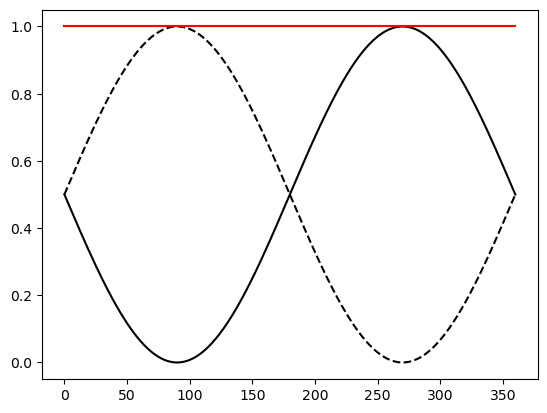

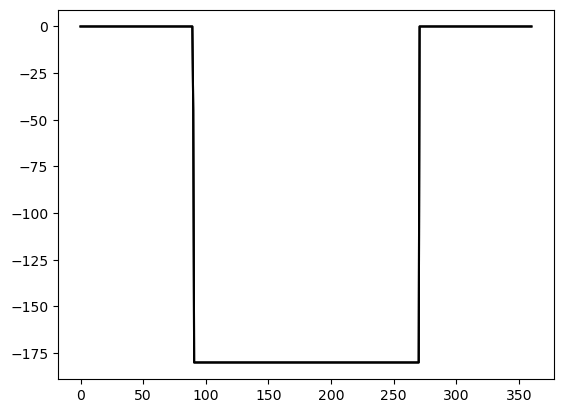

In [56]:
def wrap_phase(phase):
    phase = phase%360
    # phase_diff = np.hstack([0, np.diff(phase)])
    # phase[phase_diff>180] = phase[phase_diff>180] - 360
    # phase[phase_diff<180] = phase[phase_diff<180] + 360
    return phase

theta_arr_model = np.linspace(0, 360, 501)
theta_arr_model_rad = theta_arr_model * np.pi/180
model_B = (1/np.sqrt(2))*np.exp(1j*theta_arr_model_rad/2)*(np.sin(theta_arr_model_rad/2) + np.cos(theta_arr_model_rad/2))
model_A = (1/np.sqrt(2))*np.exp(1j*theta_arr_model_rad/2)*(np.cos(theta_arr_model_rad/2) - np.sin(theta_arr_model_rad/2))
model_A_amp, model_B_amp = np.abs(model_A), np.abs(model_B)
model_A_power, model_B_power = model_A_amp**2, model_B_amp**2
model_A_phase, model_B_phase = (180/np.pi)*np.angle(model_A), (180/np.pi)*np.angle(model_B)
model_phase_diff = (model_A_phase - model_B_phase)
model_phase_diff
# model_phase_diff[np.hstack([np.diff(model_phase_diff),0])>180] = model_phase_diff[np.hstack([np.diff(model_phase_diff),0])>180] - 360
# model_phase_diff[np.hstack([np.diff(model_phase_diff),0])<-180] = model_phase_diff[np.hstack([np.diff(model_phase_diff),0])<-180] + 360

plt.figure()
plt.plot(theta_arr_model, model_A_power, 'k')
plt.plot(theta_arr_model, model_B_power, 'k', linestyle='dashed')
plt.plot(theta_arr_model, model_A_power + model_B_power, 'r')
plt.show()

plt.figure()
plt.plot(theta_arr_model, model_phase, 'k')
plt.plot(theta_arr_model, model_phase_diff, 'k')
plt.show()

C:\Users\runner\AppData\Local\Temp\ipykernel_19672\2191237452.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('RdYlBu')


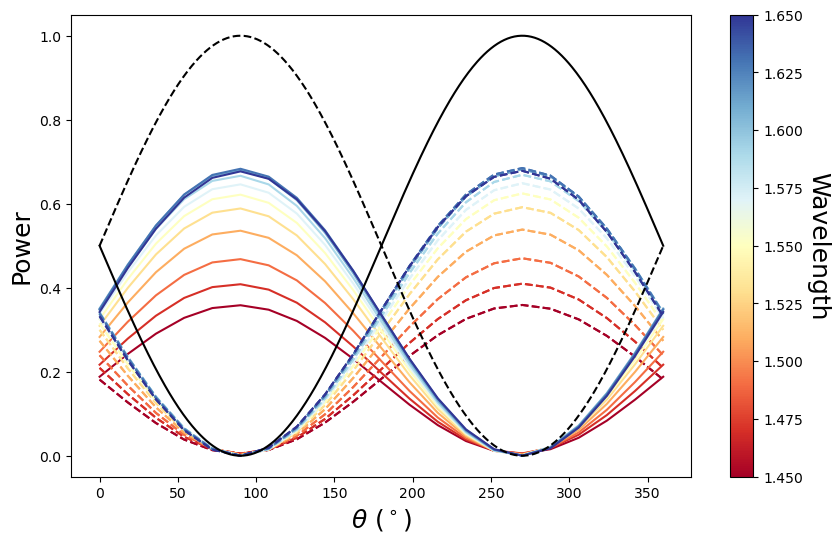

C:\Users\runner\AppData\Local\Temp\ipykernel_19672\2191237452.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('RdYlBu')


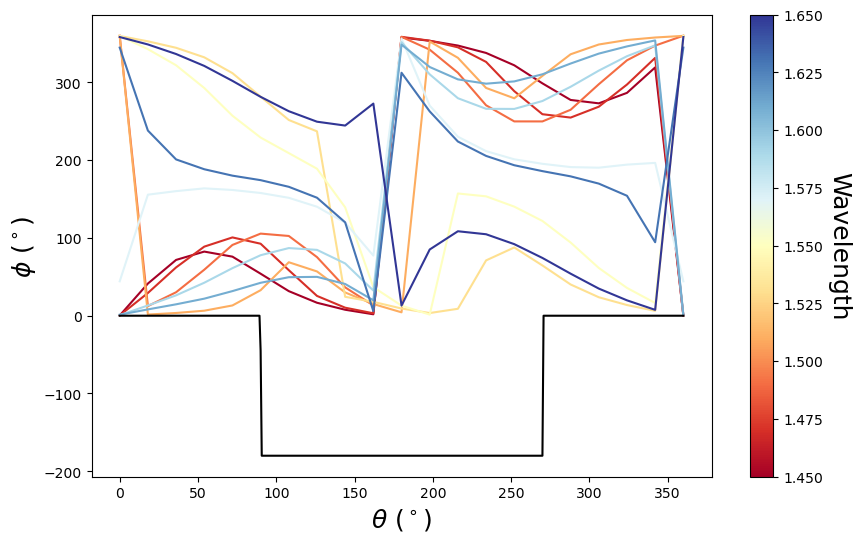

In [58]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

outputs_norm = outputs_A_amp + outputs_B_amp

fontsize = 18
fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(wav_arr), vmax=np.max(wav_arr))
cmap = cm.get_cmap('RdYlBu')
for i, wav in enumerate(wav_arr):
    color = cmap(norm(wav))
    ax.plot(theta_arr, outputs_A_amp[i], color=color)
    ax.plot(theta_arr, outputs_B_amp[i], color=color, linestyle='dashed')
    ax.plot(theta_arr, outputs_B_amp[i], color=color, linestyle='dashed')
ax.plot(theta_arr_model, model_A_power, 'k')
ax.plot(theta_arr_model, model_B_power, 'k', linestyle='dashed')
plt.xlabel(r"$\theta$ ($^\circ$)", fontsize=fontsize)
plt.ylabel("Power", fontsize=fontsize)
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength", rotation=270, fontsize=fontsize, labelpad=20)
plt.show()

# outputs_B_phase[outputs_B_phase > 180] = outputs_B_phase[outputs_B_phase > 180]%360 

fontsize = 18
fig, ax = plt.subplots(1, 1, figsize=(10,6))
norm = plt.Normalize(vmin=np.min(wav_arr), vmax=np.max(wav_arr))
cmap = cm.get_cmap('RdYlBu')
for i, wav in enumerate(wav_arr):
    color = cmap(norm(wav))
    phase_diff = (outputs_A_phase[i] - outputs_B_phase[i])%360
    # phase_diff[phase_diff>180] = phase_diff[phase_diff>180] - 360
    ax.plot(theta_arr, phase_diff, color=color)
ax.plot(theta_arr_model ,model_phase_diff, 'k')
plt.xlabel(r"$\theta$ ($^\circ$)", fontsize=fontsize)
plt.ylabel("$\phi$ ($^\circ$)", fontsize=fontsize)
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Wavelength", rotation=270, fontsize=fontsize, labelpad=20)
plt.show()

# Apply phase shift in one output and scan tricoupler in wavelength and phase

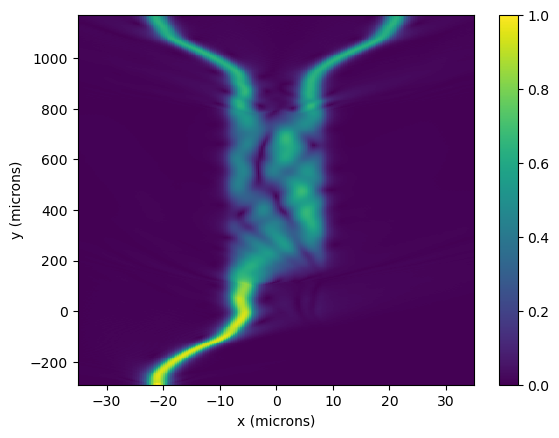

In [12]:
# filename = working_dir+save_dir+"\\2x2MMI_OneInput_scan_Wav1p550_xz.dat"
filename = "C:\\Users\\runner\\ActivePIC\\2x2MMI\\2x2MMI_OneInput_scan_Wav_Phase\\2x2MMI_OneInput_scan_Wav_Phase_Wav1p480_Phase0p000_xz.dat"
data = np.genfromtxt(filename, delimiter='', skip_header=4).T
x_line = linecache.getline(filename, 3)
y_line = linecache.getline(filename, 4)
x_line_split = x_line.split(' ')
y_line_split = y_line.split(' ')
x = np.linspace(float(x_line_split[1]), float(x_line_split[2]), int(x_line_split[0]))
y = np.linspace(float(y_line_split[1]), float(y_line_split[2]), int(y_line_split[0]))

plt.figure()
im = plt.pcolormesh(x, y, data, vmin=0, vmax=1)
plt.xlabel('x (microns)')
plt.ylabel('y (microns)')
plt.colorbar(im)
plt.show()